# Módulo 3 - Punto 3.2: Procesamiento en video y curva temporal fisiológica

Toda la lógica del cálculo está en `src/modulo3/curva_temporal.py`; este notebook se encarga de llamar a los módulos y visualizar los resultados.

Consigna: (1) segmentar y medir área/diámetro frame a frame y validar contra la medición manual (MAE/RMSE); (2) graficar A(t) o D(t); (3) extraer latencia, amplitud, velocidad de constricción y de redilatación, y reportar la variabilidad entre trials; (4) documentar las fuentes de artefactos y el método para filtrarlos o interpolarlos.

In [29]:
# --- Imports de la librería estándar ---
import sys
from pathlib import Path

# --- Configurar la raíz del repositorio ---
# Path.cwd() = carpeta desde donde corre el notebook (normalmente notebooks/).
# Subimos carpetas hasta encontrar config.yaml: esa es la raíz.
raiz = Path.cwd()
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:          # llegamos a "/" sin encontrarlo
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent

# Insertamos la raíz al principio de sys.path (posición 0 = máxima prioridad).
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))

# --- Imports de terceros y propios
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import cargar_config, ruta_absoluta
from src.modulo2 import anotacion as an
from src.modulo3 import curva_temporal as ct

## 3.2.0. Carga de Datos y Configuración Global
Se leen los parámetros desde `config.yaml` (bloque `modulo3_2`), se definen las rutas de salida y se decide el modo de trabajo: **modo video** si el archivo existe; si no, **modo CSV** con la serie ya medida en el Módulo 4.

In [30]:
# Cargar configuración global
cfg = cargar_config(raiz / "config.yaml")

# Directorio de salida de resultados
carpeta_res = raiz / "results" / "modulo3"
carpeta_res.mkdir(parents=True, exist_ok=True)

# Rutas de entrada
ruta_video = ruta_absoluta(cfg["entrada"]["video_path"])
carpeta_anot = raiz / "results" / "modulo2" / "anotaciones_manuales"
csv_m4 = raiz / "results" / "modulo4" / "4_diametro_video.csv"

# Parámetros del módulo 3.2 (si falta el bloque en config.yaml se usan estos por defecto)
p = {"paso_frames": 1, "estimulos_s": [], "ventana_basal_s": 1.0, "ventana_respuesta_s": 3.0,
     "max_hueco_s": 0.5, "sg_ventana_s": 0.3, "sg_orden": 2}
p.update(cfg.get("modulo3_2", {}))
paso_frames = p["paso_frames"]
estimulos_s = list(p["estimulos_s"])     # COMPLETAR en config.yaml con el protocolo

usar_video = ruta_video.exists()
print(f"Resultados en: {carpeta_res}")
print("Modo         :", "VIDEO" if usar_video else f"CSV (no encuentro {ruta_video.name})")
print("Estímulos    :", estimulos_s if estimulos_s else "SIN DEFINIR (se saltean los parámetros fisiológicos)")

Resultados en: c:\Users\delca\Downloads\Guia-de-imagenes-biomedicas-G9-PSIB-modulo3\Guia-de-imagenes-biomedicas-G9-PSIB-modulo3\results\modulo3
Modo         : CSV (no encuentro Video_Sofi_1.mp4)
Estímulos    : SIN DEFINIR (se saltean los parámetros fisiológicos)


## 3.2.0 Segmentación frame a frame

`ct.serie_temporal` recorre el video y, en cada frame, recorta la ROI, segmenta con Watershed(`seg.segmentar_pupila`, Módulo 2), aplica la operación morfológica final si está configurada y calcula con `descriptores_forma` (Módulo 3.1) el área, la circularidad, la excentricidad y el centroide. El diámetro es el equivalente D = 2·√(A/π)4.


In [31]:
if usar_video:
    serie = ct.serie_temporal(ruta_video, cfg, paso_frames=paso_frames)
    serie.to_csv(carpeta_res / "3_2_serie_cruda.csv", index=False)
else:
    m4 = pd.read_csv(csv_m4)
    original = m4[m4["version"] == "original"].reset_index(drop=True)
    serie = original.assign(frame=np.arange(len(original)), motivo="ok")
    serie.attrs["fs_hz"] = 1.0 / np.median(np.diff(serie["t_s"]))

fs = serie.attrs["fs_hz"]
print(f"Muestras: {len(serie)} | fs efectiva: {fs:.2f} Hz | duración cubierta: {serie['t_s'].max():.2f} s")
serie.head()

Muestras: 98 | fs efectiva: 9.98 Hz | duración cubierta: 9.72 s


,t_s,version,diametro_px,area_px,frame,motivo
0,0.000000,original,19.049233,285,0,ok
1,0.100188,original,17.947969,253,1,ok
2,0.200375,original,20.744999,338,2,ok
3,0.300563,original,23.152405,421,3,ok
4,0.400751,original,22.283703,390,4,ok


#### 3.2.1 Validación contra la medición manual (MAE / RMSE)

Se miden automáticamente los frames anotados a mano (`results/modulo2/anotaciones_manuales`) y se comparan área y diámetro. **MAE** = media de |auto − manual|; **RMSE** = raíz de la media de (auto − manual)²; **sesgo** = media de (auto − manual) (positivo = el automático sobreestima).

Se informan dos subconjuntos para no esconder nada: *todos* (una falla grosera domina el RMSE) y uno sin fallas groseras (en modo video: Dice ≥ 0,5; en modo CSV: D_auto ≤ 1,5·D_manual — criterios a justificar). Con pocos frames anotados las cifras son orientativas.

En **modo CSV** la comparación es aproximada: se usa el frame de la serie más cercano en el tiempo a cada anotación (desfase de hasta medio paso de muestreo).

In [32]:
if usar_video:
    tabla_val, resumen_val = ct.validar_contra_manual(ruta_video, cfg, carpeta_anot)
else:
    manuales = an.cargar_anotaciones(carpeta_anot)
    tabla_val, resumen_val = ct.validar_contra_serie(manuales, serie)

if tabla_val is None:
    print("No hay anotaciones manuales para validar.")
else:
    tabla_val.to_csv(carpeta_res / "3_2_validacion_por_frame.csv", index=False)
    resumen_val.to_csv(carpeta_res / "3_2_validacion_resumen.csv", index=False)
    display(tabla_val.round(2))
    display(resumen_val.round(2))

,t_manual_s,t_serie_s,desfase_s,area_manual_px,area_auto_px,diametro_manual_px,diametro_auto_px,falla_grosera
0,3.50,3.51,0.01,237,1199.0,17.37,39.07,True
1,3.84,3.81,-0.03,345,410.0,20.96,22.85,False
2,4.25,4.21,-0.04,262,395.0,18.26,22.43,False
3,8.00,8.02,0.02,179,294.0,15.10,19.35,False
4,8.49,8.52,0.02,232,1352.0,17.19,41.49,True
5,8.80,8.82,0.02,234,308.0,17.26,19.80,False


,subconjunto,magnitud,n,mae,rmse,sesgo,mae_pct
0,todos,area_px2,6,411.50,608.34,411.50,175.69
1,todos,diametro_px,6,9.81,13.58,9.81,56.84
2,sin fallas groseras,area_px2,4,96.75,100.77,96.75,41.37
3,sin fallas groseras,diametro_px,4,3.21,3.37,3.21,18.67


####  Artefactos: fuentes y método de detección

| Fuente | Qué pasa en la imagen | Cómo se detecta (`ct.detectar_artefactos`) |
|---|---|---|
| **Parpadeo completo** | El párpado tapa el iris | `estimar_pupila` devuelve `None` (contraste del iris < `contraste_min`): fila con NaN, motivo `sin_iris` |
| **Parpadeo parcial / pestañas / párpado sobre la pupila** | La máscara deja de parecerse a una elipse y el área da un salto | Caen la circularidad y sube la excentricidad (puntaje robusto con mediana/MAD, umbral `k_forma`) |
| **Movimiento ocular** (sacada, deriva) | El centroide salta respecto de su trayectoria; la pupila se ve más ovalada y el área proyectada baja sin que cambie el tamaño real | Salto del centroide respecto de su mediana móvil (umbral `k_centro`, piso de 1 px) |
| **Atípicos puntuales** (reflejos, sombras, error de Watershed) | Picos aislados de área | Filtro de **Hampel** sobre log(área): se marca lo que se aleja más de `k_hampel`·1,4826·MAD de la mediana móvil |

Dos detalles de diseño:

- **Protección contra constricciones reales:** un tramo marcado por Hampel solo queda como artefacto si la señal *vuelve al nivel de antes* (un pico). Si queda en otro nivel (un escalón), es fisiología y se desmarca. Sin esto, el filtro marcaba como atípica parte de la caída real de ~4,7 s.
- **Dilatación:** cada marca se extiende `dilatar_s` = 0,1 s a cada lado, porque los frames vecinos a un parpadeo suelen estar contaminados.

**Qué pasa con lo marcado** (`ct.limpiar_serie`): se sacan; los **huecos cortos** (≤ `max_hueco_s`) se interpolan linealmente; los **huecos largos quedan en NaN** (no se inventan datos); el suavizado Savitzky-Golay se hace tramo por tramo. Los umbrales son valores por defecto míos, no validados.

In [33]:
serie_a = ct.detectar_artefactos(serie)

criterios = ["art_sin_seg", "art_forma", "art_centro", "art_atipico"]
print("Frames marcados por criterio (antes de dilatar):")
print(serie_a[criterios].sum().to_string())
print(f"\nFrames descartados en total (con dilatación): {int(serie_a['artefacto'].sum())} de {len(serie_a)}")
if not usar_video:
    print("(Modo CSV: solo actúa el criterio de área; no hay circularidad ni centroide.)")

serie_a.loc[serie_a["artefacto"], ["t_s", "area_px", "diametro_px"] + criterios].round(2)

Frames marcados por criterio (antes de dilatar):
art_sin_seg    0
art_forma      0
art_centro     0
art_atipico    8

Frames descartados en total (con dilatación): 15 de 98
(Modo CSV: solo actúa el criterio de área; no hay circularidad ni centroide.)


,t_s,area_px,diametro_px,art_sin_seg,art_forma,art_centro,art_atipico
11,1.10,370,21.70,False,False,False,False
12,1.20,1277,40.32,False,False,False,True
13,1.30,1234,39.64,False,False,False,True
14,1.40,346,20.99,False,False,False,False
15,1.50,1231,39.59,False,False,False,True
16,1.60,341,20.84,False,False,False,False
34,3.41,439,23.64,False,False,False,False
35,3.51,1199,39.07,False,False,False,True
36,3.61,1225,39.49,False,False,False,True
37,3.71,1218,39.38,False,False,False,True


#### 3.2.1 Limpieza: descartar, interpolar huecos cortos y suavizar

In [34]:
serie_l = ct.limpiar_serie(serie_a, max_hueco_s=p["max_hueco_s"],
                           sg_ventana_s=p["sg_ventana_s"], sg_orden=p["sg_orden"])
serie_l.to_csv(carpeta_res / "3_2_serie_temporal.csv", index=False)

n_nan = int(serie_l["area_px_suave"].isna().sum())
print(f"Muestras que quedaron en NaN (huecos largos, no interpolados): {n_nan}")
if n_nan:
    print("En t =", np.round(serie_l["t_s"][serie_l["area_px_suave"].isna()].values, 2).tolist(), "s")

Muestras que quedaron en NaN (huecos largos, no interpolados): 6
En t = [1.1, 1.2, 1.3, 1.4, 1.5, 1.6] s


## 3.2.2 Curva temporal A(t) y D(t)

Gris: medición cruda. Cruces rojas: frames descartados. Azul: serie limpia. Negro: suavizada. Líneas naranjas: estímulos (si están definidos).

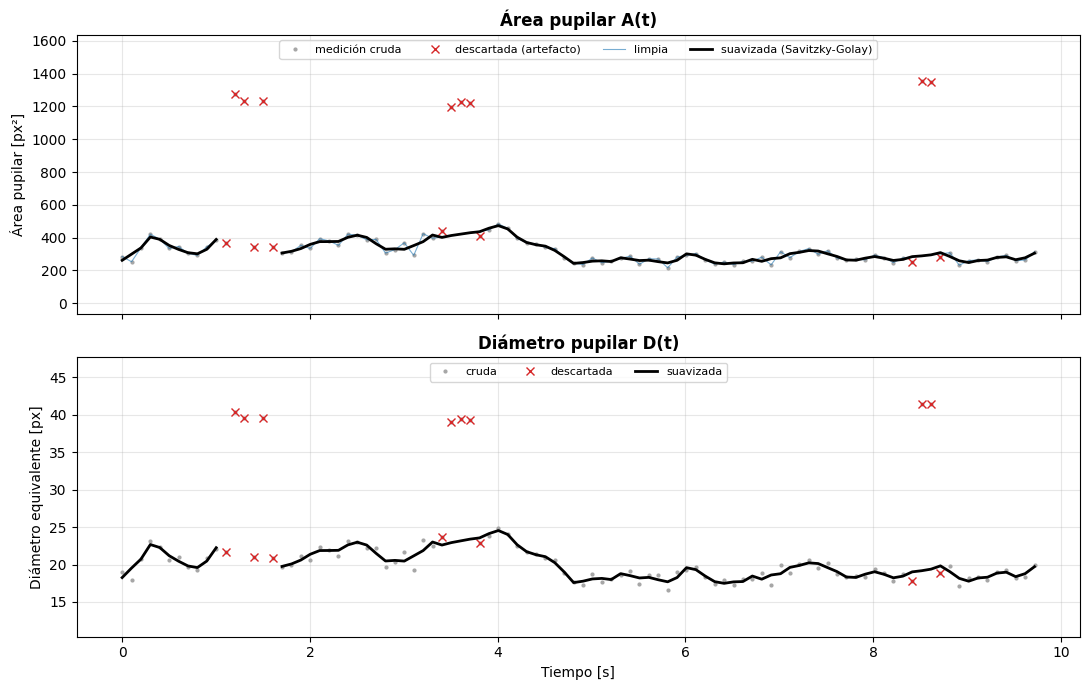

In [35]:
art = serie_l["artefacto"].to_numpy()
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

# --- Área ---
ax = axes[0]
ax.plot(serie_l["t_s"], serie_l["area_px"], ".", color="0.65", ms=4, label="medición cruda")
ax.plot(serie_l["t_s"][art], serie_l["area_px"][art], "x", color="tab:red", ms=6, label="descartada (artefacto)")
ax.plot(serie_l["t_s"], serie_l["area_px_limpia"], "-", color="tab:blue", lw=0.8, alpha=0.6, label="limpia")
ax.plot(serie_l["t_s"], serie_l["area_px_suave"], "-", color="k", lw=2, label="suavizada (Savitzky-Golay)")
ax.set_ylabel("Área pupilar [px²]")
ax.set_title("Área pupilar A(t)", fontsize=12, fontweight="bold")

# --- Diámetro equivalente ---
ax = axes[1]
d_cruda = ct.diametro_desde_area(serie_l["area_px"])
ax.plot(serie_l["t_s"], d_cruda, ".", color="0.65", ms=4, label="cruda")
ax.plot(serie_l["t_s"][art], d_cruda[art], "x", color="tab:red", ms=6, label="descartada")
ax.plot(serie_l["t_s"], ct.diametro_desde_area(serie_l["area_px_suave"]), "k-", lw=2, label="suavizada")
ax.set_ylabel("Diámetro equivalente [px]")
ax.set_xlabel("Tiempo [s]")
ax.set_title("Diámetro pupilar D(t)", fontsize=12, fontweight="bold")

for ax in axes:
    for i, te in enumerate(estimulos_s):
        ax.axvline(te, color="tab:orange", ls="--", label="estímulo" if i == 0 else None)
    ax.grid(alpha=0.3)
    ax.margins(y=0.25)                       # espacio arriba para la leyenda
    ax.legend(ncol=4, fontsize=8, loc="upper center")

plt.tight_layout()
fig.savefig(carpeta_res / "3_2_curva_temporal.png", dpi=150)
plt.show()